# NutriStrat: Multi-Label Meal Nutrient Gap Detector & Rating-Weighted Recommender

### GROUP MEMBERS:
- **Otieno Patience Atieno** - 159442
- **Omwoyo Leo Kinara** - 169956
- **Corban Chogo** - 165558

---
### Project Overview
**Question 2: Food Choices and Nutrition Dataset**  
**Expected Output Variable:** `Food_ID` / `Name` & Multi-Label Nutrient Predictions (`Protein`, `Carbs`, `Fats`, `Fiber_Vitamins`)  
This notebook implements a two-stage machine learning pipeline following the **CRISP-DM** lifecycle:
1. **Stage 1 (Multi-Label Nutrient Classification):** Uses TF-IDF text vectorization and a tuned `OneVsRestClassifier(SVC)` (benchmarked against Multinomial Naive Bayes and Decision Trees) to detect present and missing nutrients from ingredient descriptions.
2. **Stage 2 (Rating-Weighted Content Recommender):** Proposes practical local/international ingredient add-ons and ranks top-rated complementary dishes from `food.csv` using user ratings (`ratings.csv`) and cosine similarity.

## Section 1: Data Loading & Exploratory Data Analysis (Questions 3a–3d)
In this section, we load `food.csv` and `ratings.csv`, perform an inner merge on `Food_ID`, and inspect:
- **3a)** Dataset dimensions (`shape`)
- **3b)** Column data types (`dtypes`)
- **3c)** Missing values per column (`isnull().sum()`)
- **3d)** Edge sample slice (`df_sample` combining the first 15 rows and last 20 rows)

In [12]:
import os
import pandas as pd
import numpy as np

# Verify files exist in session storage
for path in ['food.csv', 'ratings.csv']:
    if not os.path.exists(path):
        raise FileNotFoundError(f"Could not find '{path}'. Please upload it to Colab session storage.")

food_df = pd.read_csv('food.csv')
ratings_df = pd.read_csv('ratings.csv')
df_merged = pd.merge(ratings_df, food_df, on='Food_ID', how='inner')

# 3a) Shape of the Merged Dataset
rows, columns = df_merged.shape
print("=== 3a) Dataset Dimensions ===")
print(f"Number of Rows: {rows}")
print(f"Number of Columns: {columns}\n")

# 3b) Column Datatypes
print("=== 3b) Data Types Breakdown ===")
print(df_merged.dtypes.value_counts())
print("\nDetailed Column Datatypes:")
print(df_merged.dtypes)

# 3c) Missing Values Assessment
print("\n=== 3c) Missing Values Per Column ===")
missing_per_col = df_merged.isnull().sum()
total_missing = missing_per_col.sum()
print(missing_per_col)
print(f"Total Missing Values: {total_missing}")
if total_missing == 0:
    print("Verdict: The dataset is complete (contains zero missing values).\n")
else:
    print(f"Verdict: The dataset is NOT complete; it contains {total_missing} missing values.\n")

# 3d) Sampling First 15 Rows and Last 20 Rows
first_15 = df_merged.head(15)
last_20 = df_merged.tail(20)
df_sample = pd.concat([first_15, last_20], ignore_index=True)
print(f"=== 3d) Sample Slice Shape: {df_sample.shape} ===")
display(df_sample)

=== 3a) Dataset Dimensions ===
Number of Rows: 511
Number of Columns: 7

=== 3b) Data Types Breakdown ===
object     4
float64    3
Name: count, dtype: int64

Detailed Column Datatypes:
User_ID     float64
Food_ID     float64
Rating      float64
Name         object
C_Type       object
Veg_Non      object
Describe     object
dtype: object

=== 3c) Missing Values Per Column ===
User_ID     0
Food_ID     0
Rating      0
Name        0
C_Type      0
Veg_Non     0
Describe    0
dtype: int64
Total Missing Values: 0
Verdict: The dataset is complete (contains zero missing values).

=== 3d) Sample Slice Shape: (35, 7) ===


,User_ID,Food_ID,Rating,Name,C_Type,Veg_Non,Describe
0,1.0,88.0,4.0,peri peri chicken satay,Snack,non-veg,"boneless skinless chicken thigh (trimmed), sal..."
1,1.0,46.0,3.0,steam bunny chicken bao,Japanese,non-veg,"buns, all purpose white flour, dry yeast, suga..."
2,1.0,24.0,5.0,green lentil dessert fudge,Dessert,veg,"whole moong beans, cow ghee, raisins, whole mi..."
3,1.0,25.0,4.0,cashew nut cookies,Dessert,veg,"cashew paste, ghee, khaand (a sweetening agent..."
4,2.0,49.0,1.0,christmas tree pizza,Italian,veg,"pizza dough (2 boules), red pepper, red onion,..."
5,2.0,33.0,8.0,moong dal kiwi coconut soup,Indian,veg,"green gram (dhuli moong dal), kiwis, coconut c..."
6,2.0,106.0,9.0,chicken nimbu dhaniya shorba,Beverage,non-veg,"water, chicken (diced)), ginger garlic paste, ..."
7,2.0,71.0,8.0,carrot ginger soup,Healthy Food,veg,"Carrots, Olive Oil, Salt, Vegetable Stock, Gin..."
8,3.0,73.0,9.0,hot chocolate,Beverage,veg,"milk, chocolate, cocoa powder, powdered sugar,..."
9,3.0,110.0,10.0,chicken and mushroom lasagna,Italian,non-veg,"chicken, salt, crush black pepper, garlic clov..."


## Section 2: Data Preparation & Weak-Supervision Nutrient Tagging
Because `food.csv` lacks quantitative calorie/gram tables, we apply **programmatic weak supervision**:
1. Aggregate `Avg_Rating` and `Rating_Count` per `Food_ID` from `ratings.csv` (imputing unrated dishes with the global rating mean).
2. Clean whitespace in `C_Type` and scan `Describe` against `NUTRIENT_KEYWORDS` (covering both international recipes and Kenyan staples such as *ugali, tilapia, omena, ndengu, sukuma, kachumbari, mursik*) to generate four binary nutrient target labels: `Protein`, `Carbs`, `Fats`, and `Fiber_Vitamins`.
3. Define `build_anchor_examples()` to inject single-ingredient anchor rows during training so rare local ingredients are not diluted.

In [13]:
NUTRIENT_KEYWORDS = {
    'Protein': [
        'chicken', 'beef', 'pork', 'mutton', 'lamb', 'goat', 'nyama', 'fish',
        'tilapia', 'omena', 'prawn', 'shrimp', 'egg', 'lentil', 'dal', 'moong',
        'ndengu', 'kamande', 'bean', 'njahi', 'chickpea', 'tofu', 'paneer',
        'yogurt', 'curd', 'mursik', 'milk', 'cheese', 'soya', 'soybean',
        'bacon', 'ham', 'turkey', 'tuna', 'sausage', 'smokie'
    ],
    'Carbs': [
        'rice', 'ugali', 'chapati', 'mandazi', 'githeri', 'mokimo', 'matoke',
        'cassava', 'nduma', 'arrowroot', 'flour', 'atta', 'maida', 'bread',
        'bun', 'pasta', 'lasagna', 'noodle', 'potato', 'chips', 'fries',
        'corn', 'oat', 'sugar', 'honey', 'tortilla', 'crepe', 'dough', 'poha',
        'semolina', 'rava', 'quinoa'
    ],
    'Fats': [
        'oil', 'butter', 'ghee', 'cream', 'almond', 'walnut', 'cashew',
        'peanut', 'groundnut', 'macadamia', 'nut', 'seed', 'flaxseed', 'chia',
        'simsim', 'sesame', 'coconut', 'avocado', 'mayonnaise', 'chocolate',
        'olive', 'chips', 'fries', 'fried'
    ],
    'Fiber_Vitamins': [
        'carrot', 'spinach', 'sukuma', 'managu', 'terere', 'sagaa', 'kunde',
        'tomato', 'onion', 'kachumbari', 'pepper', 'capsicum', 'broccoli',
        'cauliflower', 'pea', 'cabbage', 'kale', 'lettuce', 'cucumber', 'garlic',
        'ginger', 'cilantro', 'coriander', 'mushroom', 'mango', 'banana',
        'apple', 'orange', 'kiwi', 'lemon', 'pawpaw', 'papaya', 'pineapple',
        'vegetable', 'herb', 'basil'
    ]
}

TARGET_COLS = ['Protein', 'Carbs', 'Fats', 'Fiber_Vitamins']

def load_and_prepare_data(food_path='food.csv', ratings_path='ratings.csv'):
    food_df = pd.read_csv(food_path)
    ratings_df = pd.read_csv(ratings_path)

    df = food_df.copy()
    df['C_Type'] = df['C_Type'].fillna('').str.strip()
    df['Describe'] = df['Describe'].fillna('').str.lower()

    # Aggregate mean user rating and count per Food_ID
    rating_stats = ratings_df.groupby('Food_ID').agg(
        Avg_Rating=('Rating', 'mean'),
        Rating_Count=('Rating', 'count')
    ).reset_index()

    df = pd.merge(df, rating_stats, on='Food_ID', how='left')
    global_mean = ratings_df['Rating'].mean()
    df['Avg_Rating'] = df['Avg_Rating'].fillna(global_mean).round(2)
    df['Rating_Count'] = df['Rating_Count'].fillna(0).astype(int)

    # Generate binary nutrient labels
    for nutrient, keywords in NUTRIENT_KEYWORDS.items():
        df[nutrient] = df['Describe'].apply(
            lambda text: 1 if any(word in text for word in keywords) else 0
        )
    return df

def build_anchor_examples(repeat=5):
    rows = []
    for _ in range(repeat):
        for nutrient, words in NUTRIENT_KEYWORDS.items():
            for word in words:
                row = {'Describe': word}
                for col in TARGET_COLS:
                    row[col] = 1 if col == nutrient else 0
                rows.append(row)
    return pd.DataFrame(rows)

enriched_df = load_and_prepare_data('food.csv', 'ratings.csv')
print("Enriched Catalog Shape:", enriched_df.shape)
print("\nNutrient Positive Label Counts across 400 Dishes:")
print(enriched_df[TARGET_COLS].sum())
display(enriched_df.head(5))

Enriched Catalog Shape: (400, 11)

Nutrient Positive Label Counts across 400 Dishes:
Protein           286
Carbs             266
Fats              318
Fiber_Vitamins    308
dtype: int64


,Food_ID,Name,C_Type,Veg_Non,Describe,Avg_Rating,Rating_Count,Protein,Carbs,Fats,Fiber_Vitamins
0,1,summer squash salad,Healthy Food,veg,"white balsamic vinegar, lemon juice, lemon rin...",7.5,2,0,0,1,1
1,2,chicken minced salad,Healthy Food,non-veg,"olive oil, chicken mince, garlic (minced), oni...",6.0,3,1,0,1,1
2,3,sweet chilli almonds,Snack,veg,"almonds whole, egg white, curry leaves, salt, ...",4.0,2,1,1,1,0
3,4,tricolour salad,Healthy Food,veg,"vinegar, honey/sugar, soy sauce, salt, garlic ...",6.0,2,0,1,1,1
4,5,christmas cake,Dessert,veg,"christmas dry fruits (pre-soaked), orange zest...",6.5,6,1,1,1,1


## Section 3: Baseline Model Training & Comparative Benchmark
We split `enriched_df` into an **80% training set** (augmented with single-ingredient anchor examples) and a **20% held-out test set** (`random_state=42`). Using `TfidfVectorizer(stop_words='english', max_features=2000)`, we benchmark three multi-label classifiers wrapped in `OneVsRestClassifier`:
1. **Support Vector Machine (`SVC`, RBF Kernel)** — Primary candidate model
2. **Multinomial Naive Bayes (`MultinomialNB`)** — Probabilistic baseline
3. **Decision Tree (`DecisionTreeClassifier`)** — Rule-based baseline

=== Stage 1 Baseline Model Comparison
                    Model  Micro-F1  Macro-F1  Exact Match Acc  Macro ROC-AUC
         SVM (RBF Kernel)    0.9205    0.9188           0.5750         0.9465
Naive Bayes (Multinomial)    0.9137    0.9109           0.5750         0.9304
            Decision Tree    0.9457    0.9455           0.7375         0.9486

=== Baseline SVM Classification Report ===
                precision    recall  f1-score   support

       Protein       0.88      0.93      0.90        56
         Carbs       0.83      0.96      0.89        50
          Fats       0.94      0.98      0.96        63
Fiber_Vitamins       0.94      0.91      0.92        64

     micro avg       0.90      0.94      0.92       233
     macro avg       0.90      0.94      0.92       233
  weighted avg       0.90      0.94      0.92       233
   samples avg       0.88      0.92      0.89       233



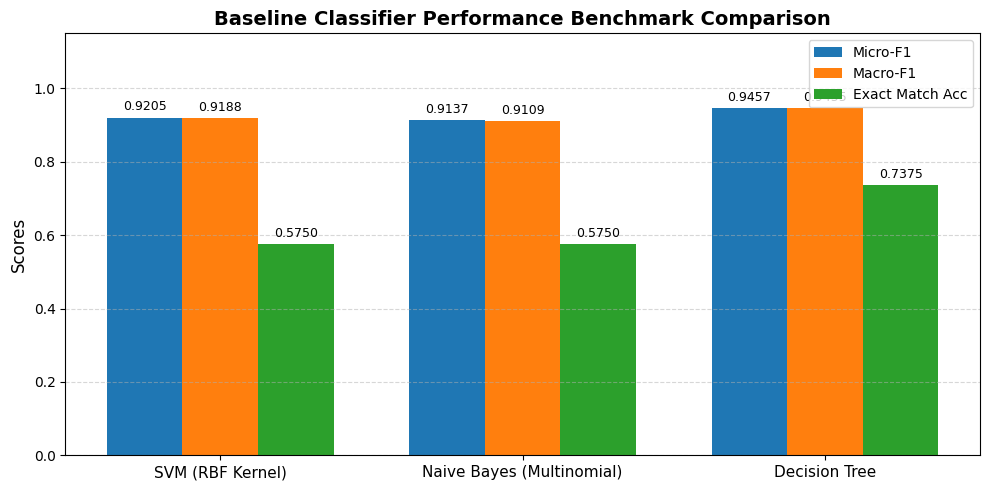

In [19]:
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score

DEFAULT_THRESHOLD = 0.50

# 80/20 Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(
    enriched_df['Describe'], enriched_df[TARGET_COLS], test_size=0.2, random_state=42
)

# Augment training data with single-ingredient anchors
anchors_df = build_anchor_examples(repeat=5)
X_train_aug = pd.concat([X_train, anchors_df['Describe']], ignore_index=True)
y_train_aug = pd.concat([y_train, anchors_df[TARGET_COLS]], ignore_index=True)

# Fit TF-IDF Vectorizer
tfidf_vec = TfidfVectorizer(stop_words='english', max_features=2000)
X_train_vec = tfidf_vec.fit_transform(X_train_aug)
X_test_vec = tfidf_vec.transform(X_test)

baseline_models = {
    'SVM (RBF Kernel)': OneVsRestClassifier(
        SVC(kernel='rbf', C=5.0, probability=True, class_weight='balanced', random_state=42)
    ),
    'Naive Bayes (Multinomial)': OneVsRestClassifier(MultinomialNB()),
    'Decision Tree': OneVsRestClassifier(
        DecisionTreeClassifier(max_depth=12, random_state=42)
    ),
}

benchmark_results = []
benchmark_results = []
for name, clf in baseline_models.items():
  clf.fit(X_train_vec, y_train_aug)
  y_probs = clf.predict_proba(X_test_vec)
  y_pred = (y_probs >= DEFAULT_THRESHOLD).astype(int)
  benchmark_results.append({
      'Model': name,
      'Accuracy (Exact Match)': round(accuracy_score(y_test, y_pred), 4),
      'Precision (Macro)': round(
          precision_score(y_test, y_pred, average='macro', zero_division=0), 4
      ),
      'Recall (Macro)': round(
          recall_score(y_test, y_pred, average='macro', zero_division=0), 4
      ),
      'F1-Score (Macro)': round(
          f1_score(y_test, y_pred, average='macro', zero_division=0), 4
      ),
      'ROC-AUC (Macro)': round(
          roc_auc_score(y_test, y_probs, average='macro'), 4
      ),
  })
print("=== Stage 1 Baseline Model Comparison")
print(df_bench.to_string(index=False))

# Detailed report for baseline SVM
baseline_svm = baseline_models['SVM (RBF Kernel)']
y_base_svm_pred = (baseline_svm.predict_proba(X_test_vec) >= DEFAULT_THRESHOLD).astype(int)
print("\n=== Baseline SVM Classification Report ===")
print(classification_report(y_test, y_base_svm_pred, target_names=TARGET_COLS, zero_division=0))

# Plot Baseline Comparison Bar Chart
x = np.arange(len(df_bench['Model']))
width = 0.25
fig, ax = plt.subplots(figsize=(10, 5))
rects1 = ax.bar(x - width, df_bench['Micro-F1'], width, label='Micro-F1', color='#1f77b4')
rects2 = ax.bar(x, df_bench['Macro-F1'], width, label='Macro-F1', color='#ff7f0e')
rects3 = ax.bar(x + width, df_bench['Exact Match Acc'], width, label='Exact Match Acc', color='#2ca02c')

ax.set_ylabel('Scores', fontsize=12)
ax.set_title('Baseline Classifier Performance Benchmark Comparison', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(df_bench['Model'], fontsize=11)
ax.set_ylim(0, 1.15)
ax.legend(loc='upper right', fontsize=10)
ax.grid(axis='y', linestyle='--', alpha=0.5)

for rects in [rects1, rects2, rects3]:
    for rect in rects:
        h = rect.get_height()
        ax.annotate(f'{h:.4f}', xy=(rect.get_x() + rect.get_width() / 2, h),
                    xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

## Section 4: Automated Hyperparameter Tuning (`GridSearchCV`)
To optimize our primary SVM classifier, we perform  cross-validated `GridSearchCV` across regularization parameter `C` (`[0.1, 1.0, 5.0, 10.0]`), kernel type (`['linear', 'rbf']`), and kernel coefficient `gamma` (`['scale', 'auto']`) optimizing `f1_micro`.

Initiating Automated Hyperparameter Tuning using GridSearchCV...
Fitting 3 folds for each of 16 candidates, totalling 48 fits

OPTIMIZED SVM PERFORMANCE METRICS
Best Hyperparameters   : {'estimator__C': 5.0, 'estimator__gamma': 'scale', 'estimator__kernel': 'linear'}
Accuracy (Exact Match) : 0.6625
Precision (Macro)      : 0.9188
Recall (Macro)         : 0.9397
F1-Score (Macro)       : 0.9290
ROC-AUC Score (Macro)  : 0.9535


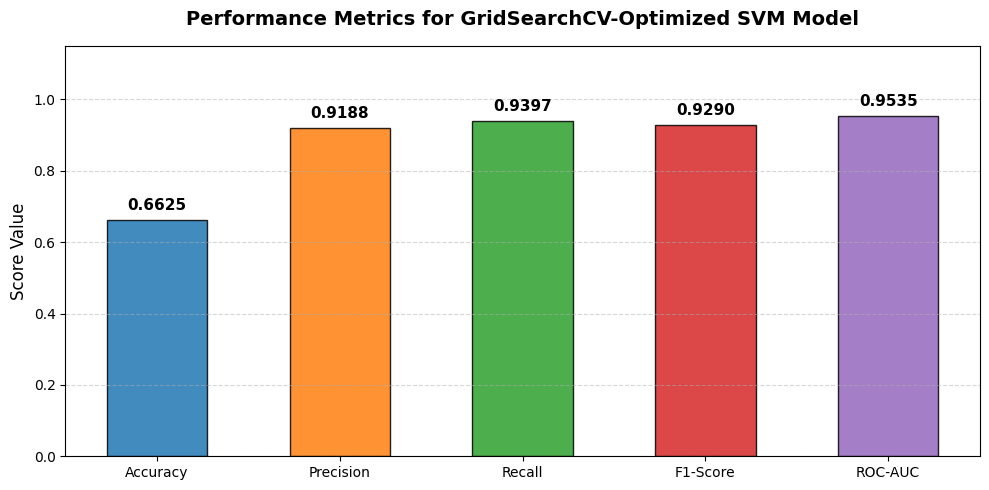

In [15]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import precision_score, recall_score

base_estimator = SVC(probability=True, class_weight='balanced', random_state=42)
ovr_classifier = OneVsRestClassifier(base_estimator)

param_grid = {
    'estimator__C': [0.1, 1.0, 5.0, 10.0],
    'estimator__kernel': ['linear', 'rbf'],
    'estimator__gamma': ['scale', 'auto']
}

print("Initiating Automated Hyperparameter Tuning using GridSearchCV...")
grid_search = GridSearchCV(
    estimator=ovr_classifier,
    param_grid=param_grid,
    scoring='f1_micro',
    cv=3,
    n_jobs=-1,
    verbose=1
)
grid_search.fit(X_train_vec, y_train_aug)

best_svm_model = grid_search.best_estimator_
y_opt_probs = best_svm_model.predict_proba(X_test_vec)
y_opt_pred = (y_opt_probs >= DEFAULT_THRESHOLD).astype(int)

opt_accuracy = accuracy_score(y_test, y_opt_pred)
opt_precision = precision_score(y_test, y_opt_pred, average='macro', zero_division=0)
opt_recall = recall_score(y_test, y_opt_pred, average='macro', zero_division=0)
opt_f1 = f1_score(y_test, y_opt_pred, average='macro', zero_division=0)
opt_roc_auc = roc_auc_score(y_test, y_opt_probs, average='macro')

print("\n=========================================")
print("OPTIMIZED SVM PERFORMANCE METRICS")
print("=========================================")
print(f"Best Hyperparameters   : {grid_search.best_params_}")
print(f"Accuracy (Exact Match) : {opt_accuracy:.4f}")
print(f"Precision (Macro)      : {opt_precision:.4f}")
print(f"Recall (Macro)         : {opt_recall:.4f}")
print(f"F1-Score (Macro)       : {opt_f1:.4f}")
print(f"ROC-AUC Score (Macro)  : {opt_roc_auc:.4f}")

# Plot Optimized SVM Metrics
metrics_names = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']
metrics_values = [opt_accuracy, opt_precision, opt_recall, opt_f1, opt_roc_auc]
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']

plt.figure(figsize=(10, 5))
bars = plt.bar(metrics_names, metrics_values, color=colors, width=0.55, edgecolor='black', alpha=0.85)
plt.title('Performance Metrics for GridSearchCV-Optimized SVM Model', fontsize=14, fontweight='bold', pad=15)
plt.ylabel('Score Value', fontsize=12)
plt.ylim(0, 1.15)
plt.grid(axis='y', linestyle='--', alpha=0.5)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2.0, yval + 0.02, f'{yval:.4f}',
             ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

## Section 5: Probability Threshold Optimization & Artifact Export
Next, we sweep decision thresholds from `0.10` to `0.95` on our tuned `best_svm_model` to select the optimal cutoff balancing Macro-F1 and Exact Match Accuracy, and serialize the final artifacts (`nutristrat_tfidf.joblib`, `nutristrat_svm.joblib`, and `enriched_food_data.csv`) for deployment in the Streamlit demo UI (`app.py`).

=== Threshold Optimization Sweep (Tuned SVM) ===


,Threshold,Micro-F1,Macro-F1,Exact Match Acc
0,0.100000,0.894500,0.893100,0.437500
1,0.150000,0.908700,0.907400,0.537500
2,0.200000,0.909500,0.908100,0.550000
3,0.250000,0.910900,0.909400,0.562500
4,0.300000,0.915800,0.914100,0.612500
5,0.350000,0.919300,0.917500,0.637500
6,0.400000,0.924400,0.923100,0.625000
7,0.450000,0.930200,0.929300,0.650000
8,0.500000,0.929600,0.928700,0.650000
9,0.550000,0.929300,0.927800,0.650000



Selected Optimal Decision Threshold: 0.60


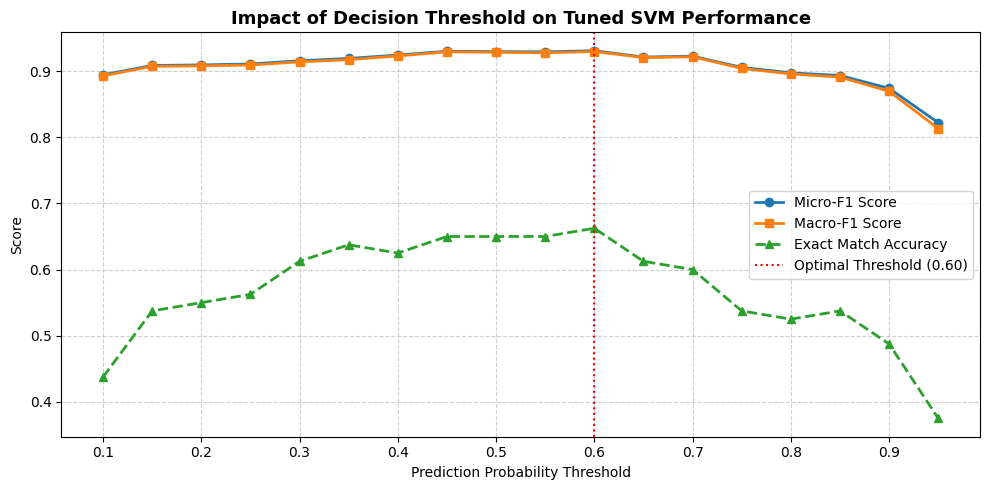

Exported final tuned artifacts: nutristrat_tfidf.joblib, nutristrat_svm.joblib, enriched_food_data.csv


In [16]:
import joblib

threshold_grid = np.arange(0.10, 1.00, 0.05)
sweep_results = []

for t in threshold_grid:
    y_pred_temp = (y_opt_probs >= t).astype(int)
    sweep_results.append({
        'Threshold': round(t, 2),
        'Micro-F1': round(f1_score(y_test, y_pred_temp, average='micro'), 4),
        'Macro-F1': round(f1_score(y_test, y_pred_temp, average='macro'), 4),
        'Exact Match Acc': round(accuracy_score(y_test, y_pred_temp), 4)
    })

df_sweep = pd.DataFrame(sweep_results)
print("=== Threshold Optimization Sweep (Tuned SVM) ===")
display(df_sweep.style.highlight_max(axis=0, color='lightgreen', subset=['Micro-F1', 'Macro-F1', 'Exact Match Acc']))

# Automatically pick threshold maximizing Macro-F1
OPTIMAL_THRESHOLD = float(df_sweep.loc[df_sweep['Macro-F1'].idxmax(), 'Threshold'])
print(f"\nSelected Optimal Decision Threshold: {OPTIMAL_THRESHOLD:.2f}")

# Plot Threshold Curve
plt.figure(figsize=(10, 5))
plt.plot(df_sweep['Threshold'], df_sweep['Micro-F1'], label='Micro-F1 Score', marker='o', linewidth=2)
plt.plot(df_sweep['Threshold'], df_sweep['Macro-F1'], label='Macro-F1 Score', marker='s', linewidth=2)
plt.plot(df_sweep['Threshold'], df_sweep['Exact Match Acc'], label='Exact Match Accuracy', marker='^', linewidth=2, linestyle='--')
plt.axvline(OPTIMAL_THRESHOLD, color='red', linestyle=':', label=f'Optimal Threshold ({OPTIMAL_THRESHOLD:.2f})')

plt.title('Impact of Decision Threshold on Tuned SVM Performance', fontsize=13, fontweight='bold')
plt.xlabel('Prediction Probability Threshold')
plt.ylabel('Score')
plt.xticks(np.arange(0.1, 1.0, 0.1))
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

# Export Tuned Model Artifacts for Streamlit UI
joblib.dump(tfidf_vec, 'nutristrat_tfidf.joblib')
joblib.dump(best_svm_model, 'nutristrat_svm.joblib')
enriched_df.to_csv('enriched_food_data.csv', index=False)
print("Exported final tuned artifacts: nutristrat_tfidf.joblib, nutristrat_svm.joblib, enriched_food_data.csv")

## Section 6: End-to-End Meal Diagnosis & Rating-Weighted Recommender Demo
Finally, we connect Stage 1 (`diagnose_meal` with synonym normalization for local terms like *chips* and *fries*) to Stage 2 (`recommend_meal_improvements`), suggesting practical add-ons and top-rated non-dessert dishes from `enriched_df` to balance sample Kenyan and international meals.

In [17]:
import re
from sklearn.metrics.pairwise import cosine_similarity

SYNONYM_MAP = {
    'french fries': 'potato oil',
    'fries': 'potato oil',
    'chips': 'potato oil',
    'bhajia': 'potato flour oil',
    'smokie': 'sausage beef',
    'mayai': 'egg',
    'nyama': 'beef',
    'kuku': 'chicken',
    'samaki': 'fish',
    'maharagwe': 'beans',
    'wali': 'rice'
}

VEG_ADDONS = {
    'Protein': ['lentils (ndengu/dal)', 'beans or chickpeas', 'tofu or paneer', 'Greek yogurt'],
    'Carbs': ['steamed brown rice', 'whole-wheat chapati', 'roasted sweet potatoes', 'ugali or quinoa'],
    'Fats': ['sliced avocado', 'a drizzle of olive oil', 'crushed peanuts, walnuts, or almonds', 'flaxseeds/simsim'],
    'Fiber_Vitamins': ['steamed sukuma wiki or spinach', 'fresh kachumbari (tomatoes & onions)', 'steamed cabbage or carrots', 'broccoli']
}

NON_VEG_ADDONS = {
    'Protein': ['grilled chicken breast', 'boiled eggs', 'pan-seared tilapia or prawns', 'lentils or beans'],
    'Carbs': VEG_ADDONS['Carbs'],
    'Fats': VEG_ADDONS['Fats'],
    'Fiber_Vitamins': VEG_ADDONS['Fiber_Vitamins']
}

def normalize_meal_text(text):
    cleaned = text.lower().strip()
    for phrase, replacement in SYNONYM_MAP.items():
        if phrase in cleaned:
            cleaned = cleaned.replace(phrase, replacement)
    return cleaned

def diagnose_meal(user_meal_text, vectorizer, classifier, threshold=OPTIMAL_THRESHOLD):
    normalized = normalize_meal_text(user_meal_text)
    parts = [p.strip() for p in re.split(r',|\band\b|\bwith\b|\bplus\b', normalized) if p.strip()]
    texts_to_score = [normalized] + parts

    vecs = vectorizer.transform(texts_to_score)
    max_probs = classifier.predict_proba(vecs).max(axis=0)

    present = [n for n, p in zip(TARGET_COLS, max_probs) if p >= threshold]
    missing = [n for n, p in zip(TARGET_COLS, max_probs) if p < threshold]

    return {
        'input_meal': user_meal_text,
        'present_nutrients': present,
        'missing_nutrients': missing,
        'is_balanced': len(missing) == 0
    }

def recommend_meal_improvements(diagnosis, catalog_df, is_veg=None, cuisine=None, top_n=3):
    missing = diagnosis['missing_nutrients']
    if not missing:
        return {
            'status': 'Balanced Meal!',
            'message': 'Great job! Your meal already covers Protein, Carbs, Healthy Fats, and Fiber/Vitamins.',
            'ingredient_additions': {},
            'recommended_sides': pd.DataFrame()
        }

    addon_bank = VEG_ADDONS if (is_veg is True or str(is_veg).lower() == 'veg') else NON_VEG_ADDONS
    additions = {nutrient: addon_bank[nutrient][:3] for nutrient in missing}

    candidates = catalog_df[catalog_df['C_Type'].str.lower() != 'dessert'].copy()
    if is_veg is True or str(is_veg).lower() == 'veg':
        candidates = candidates[candidates['Veg_Non'].str.lower() == 'veg']
    elif is_veg is False or str(is_veg).lower() == 'non-veg':
        candidates = candidates[candidates['Veg_Non'].str.lower() == 'non-veg']

    if cuisine:
        cuisine_matches = candidates[candidates['C_Type'].str.lower() == cuisine.lower()]
        if not cuisine_matches.empty:
            candidates = cuisine_matches

    candidates['Missing_Covered'] = candidates[missing].sum(axis=1)
    candidates['Healthy_Bonus'] = (candidates['C_Type'].str.lower() == 'healthy food').astype(int) * 0.4
    candidates['Rating_Boost'] = (candidates['Avg_Rating'] / 10.0) * 0.5

    target_query = " ".join([" ".join(NUTRIENT_KEYWORDS[m]) for m in missing])
    sim_vec = TfidfVectorizer(stop_words='english')
    tfidf_mat = sim_vec.fit_transform(candidates['Describe'])
    candidates['Similarity'] = cosine_similarity(sim_vec.transform([target_query]), tfidf_mat).flatten()

    candidates['Balance_Score'] = (
        candidates['Missing_Covered']
        + candidates['Healthy_Bonus']
        + candidates['Rating_Boost']
        + candidates['Similarity']
    )

    valid_sides = candidates[candidates['Missing_Covered'] > 0]
    top_sides = valid_sides.sort_values(by='Balance_Score', ascending=False).head(top_n)
    display_cols = ['Food_ID', 'Name', 'C_Type', 'Veg_Non', 'Avg_Rating'] + missing

    return {
        'status': 'Needs Balancing',
        'message': f"Your meal is missing: {', '.join(missing)}.",
        'ingredient_additions': additions,
        'recommended_sides': top_sides[display_cols]
    }

# Run End-to-End Verification
test_meals = [
    "Ugali and tilapia",
    "French fries",
    "Rice, Chicken, avocado, cabbage",
    "Chapati and ndengu",
    "Plain pasta with butter"
]

for meal in test_meals:
    diag = diagnose_meal(meal, tfidf_vec, best_svm_model)
    rec = recommend_meal_improvements(diag, enriched_df, is_veg=None)

    print("\n==========================================")
    print(f"INPUT MEAL : {diag['input_meal']}")
    print(f"PRESENT    : {diag['present_nutrients']}")
    print(f"MISSING    : {diag['missing_nutrients']}")
    print(f"VERDICT    : {rec['status']} — {rec['message']}")
    if rec['ingredient_additions']:
        print("ADD TO MEAL:", rec['ingredient_additions'])
    if not rec['recommended_sides'].empty:
        print("\nTOP RATED COMPLEMENTARY DISHES FROM DATASET:")
        print(rec['recommended_sides'].to_string(index=False))


INPUT MEAL : Ugali and tilapia
PRESENT    : ['Protein', 'Carbs']
MISSING    : ['Fats', 'Fiber_Vitamins']
VERDICT    : Needs Balancing — Your meal is missing: Fats, Fiber_Vitamins.
ADD TO MEAL: {'Fats': ['sliced avocado', 'a drizzle of olive oil', 'crushed peanuts, walnuts, or almonds'], 'Fiber_Vitamins': ['steamed sukuma wiki or spinach', 'fresh kachumbari (tomatoes & onions)', 'steamed cabbage or carrots']}

TOP RATED COMPLEMENTARY DISHES FROM DATASET:
 Food_ID                     Name       C_Type Veg_Non  Avg_Rating  Fats  Fiber_Vitamins
      40 corn and raw mango salad Healthy Food     veg        10.0     1               1
     282         fruit cube salad Healthy Food     veg        10.0     1               1
     109   chicken quinoa biryani Healthy Food non-veg        10.0     1               1

INPUT MEAL : French fries
PRESENT    : ['Carbs', 'Fats']
MISSING    : ['Protein', 'Fiber_Vitamins']
VERDICT    : Needs Balancing — Your meal is missing: Protein, Fiber_Vitamins.
ADD TO